# 20nodes_ModMultiOmics_obsconf0_latconf0_Laplace_Mixed: tuned



In [1]:
from pathlib import Path
import sys, os, json
ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents) if (p / "experiments/run_model.py").is_file()), None)
if ROOT is None:
    raise RuntimeError("Open this notebook from inside the repository.")
os.environ.setdefault("MPLCONFIGDIR", str(ROOT / ".cache/matplotlib"))
sys.path[:0] = [str(ROOT / "analysis"), str(ROOT / "experiments")]
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
import final_visualization as fv
import result_tables as th
fv.apply_style()
th.ensure_output_dirs("tuned")
from scipy.stats import spearmanr
from varsortability import calculate_varsortability
from condition_data import load_sample, sample_path


def sortability(frame, study):
    rows = []
    for family, seed in (
        frame[["dataset", "dataset_seed"]].drop_duplicates().itertuples(index=False, name=None)
    ):
        path = sample_path({"tuned": "evaluation"}.get(study, study), family)
        with load_sample(study, family, int(seed)) as data:
            raw = "X_raw" in data.files
            result = calculate_varsortability(data["X_raw"] if raw else data["X"], data["true_adj"])
            if not raw:
                for key in (
                    "varsortability",
                    "n_ordered_variance_paths",
                    "n_tied_variance_paths",
                ):
                    result[key] = np.nan
        rows.append(
            dict(
                dataset=family,
                dataset_seed=seed,
                study=study,
                raw_variance_available=raw,
                sample_path=str(path.relative_to(ROOT)),
                **result,
            )
        )
    return pd.DataFrame(rows)


In [2]:


output = ROOT / "results"
output.mkdir(parents=True, exist_ok=True)
sources = th.load_aligned_sources()
main = sources["benchmark_with_biological"]
complete = sources["complete"]
correlations = []
(output / "tuned" / "by_family" / '20nodes_ModMultiOmics_obsconf0_latconf0_Laplace_Mixed').mkdir(parents=True, exist_ok=True)


## Metrics, seed stability and sortability


,model,mean,std,size
0,AVICI,0.568269,0.106939,15
1,DAGMA_Linear,0.369748,0.084880,15
2,DAGMA_Nonlinear,0.479187,0.103520,15
3,DAS,0.494259,0.114706,15
4,DirectLiNGAM,0.348454,0.117468,15
5,FCI,0.277736,0.126324,15
6,GES,0.408423,0.124863,15
7,GOLEM,0.397663,0.130302,15
8,GRaSP,0.445899,0.108043,15
9,GraNDAG,0.290165,0.255996,15


,model,mean,std,size
0,AVICI,18.666667,3.976119,15
1,DAGMA_Linear,23.333333,3.754363,15
2,DAGMA_Nonlinear,21.120000,3.520390,15
3,DAS,25.466667,6.664047,15
4,DirectLiNGAM,26.000000,4.750940,15
5,FCI,25.240000,5.281342,15
6,GES,25.866667,5.083119,15
7,GOLEM,24.333333,5.802298,15
8,GRaSP,25.613333,5.099281,15
9,GraNDAG,22.800000,5.906413,15


,model,mean,std,size
0,AVICI,0.711821,0.099666,15
1,DAGMA_Linear,0.447524,0.086475,15
2,DAGMA_Nonlinear,0.642462,0.135407,15
3,DAS,0.447843,0.117707,15
4,DirectLiNGAM,0.364617,0.121593,15
5,FCI,0.610897,0.213388,15
6,GES,0.476030,0.145947,15
7,GOLEM,0.474680,0.172718,15
8,GRaSP,0.542809,0.120329,15
9,GraNDAG,0.550650,0.319667,15


,model,mean,std,size
0,AVICI,0.482117,0.112311,15
1,DAGMA_Linear,0.318498,0.089736,15
2,DAGMA_Nonlinear,0.389677,0.093131,15
3,DAS,0.555523,0.115746,15
4,DirectLiNGAM,0.339791,0.126091,15
5,FCI,0.185904,0.092191,15
6,GES,0.362744,0.119519,15
7,GOLEM,0.347392,0.110842,15
8,GRaSP,0.382422,0.104785,15
9,GraNDAG,0.230569,0.244732,15


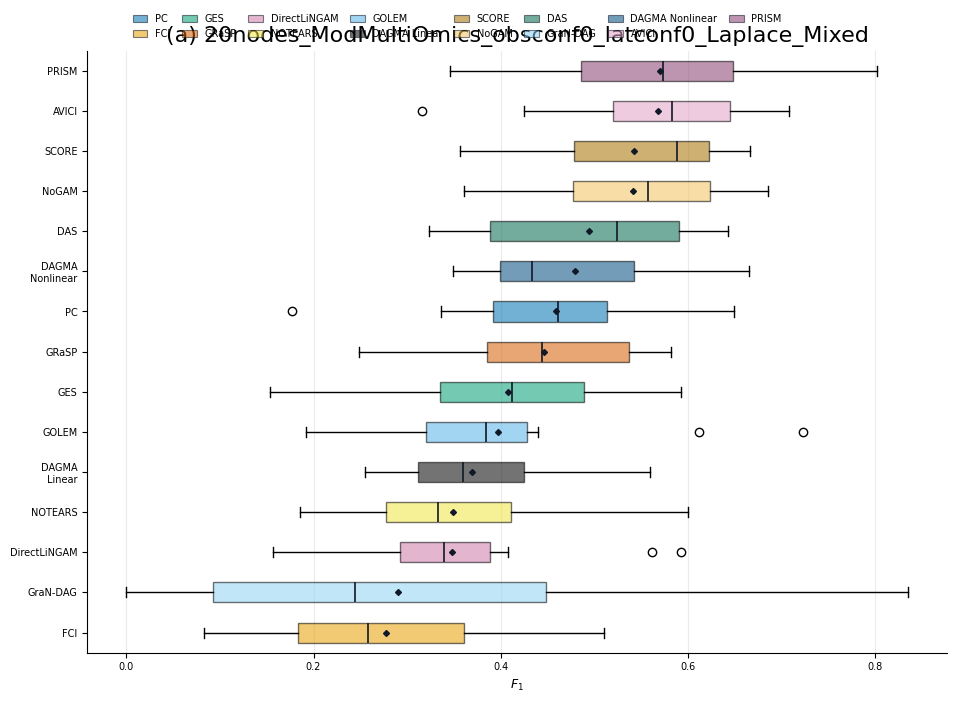

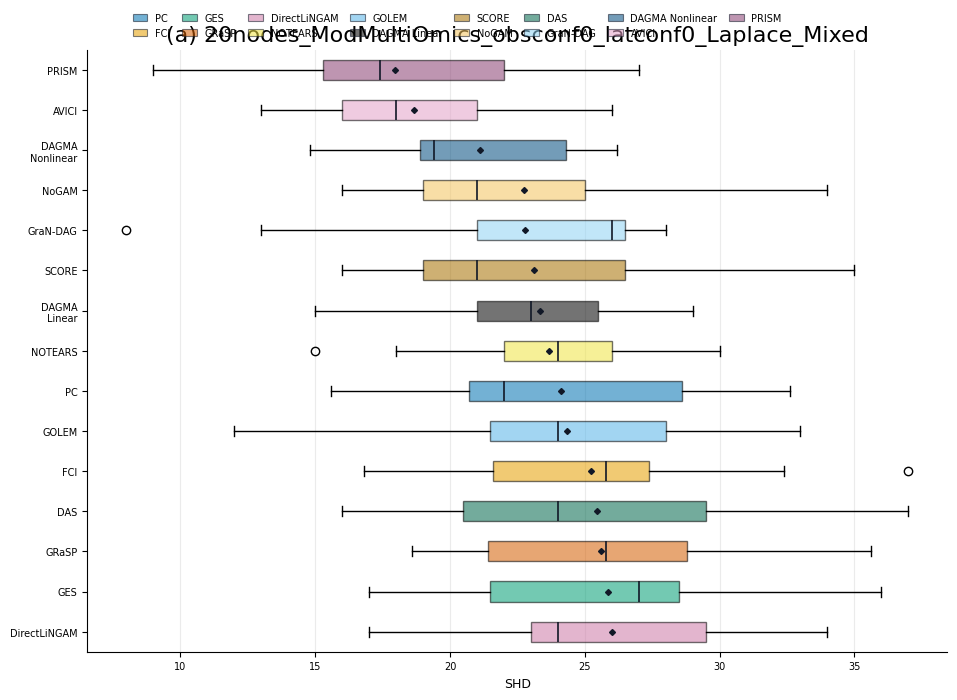

,dataset_seed,model,f1_range
0,19,AVICI,0.000000
1,19,DAGMA_Linear,0.000000
2,19,DAGMA_Nonlinear,0.095238
3,19,DAS,0.000000
4,19,DirectLiNGAM,0.000000
5,19,FCI,0.250000
6,19,GES,0.000000
7,19,GOLEM,0.000000
8,19,GRaSP,0.265457
9,19,GraNDAG,0.000000


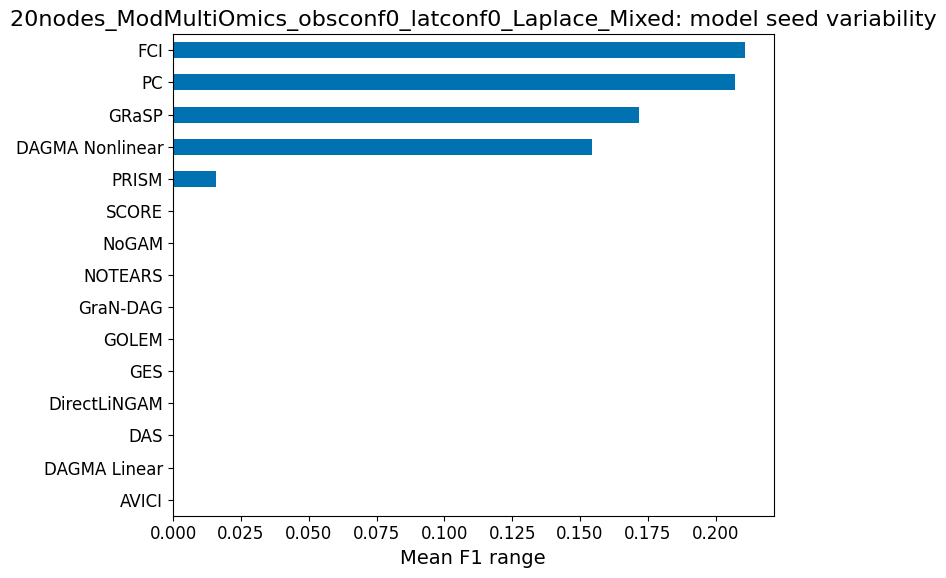

,model_seed,model,f1_range
0,0,AVICI,0.392544
1,0,DAGMA_Linear,0.304681
2,0,DAGMA_Nonlinear,0.400742
3,0,DAS,0.319328
4,0,DirectLiNGAM,0.435730
5,0,FCI,0.585366
6,0,GES,0.438746
7,0,GOLEM,0.531097
8,0,GRaSP,0.430643
9,0,GraNDAG,0.835821


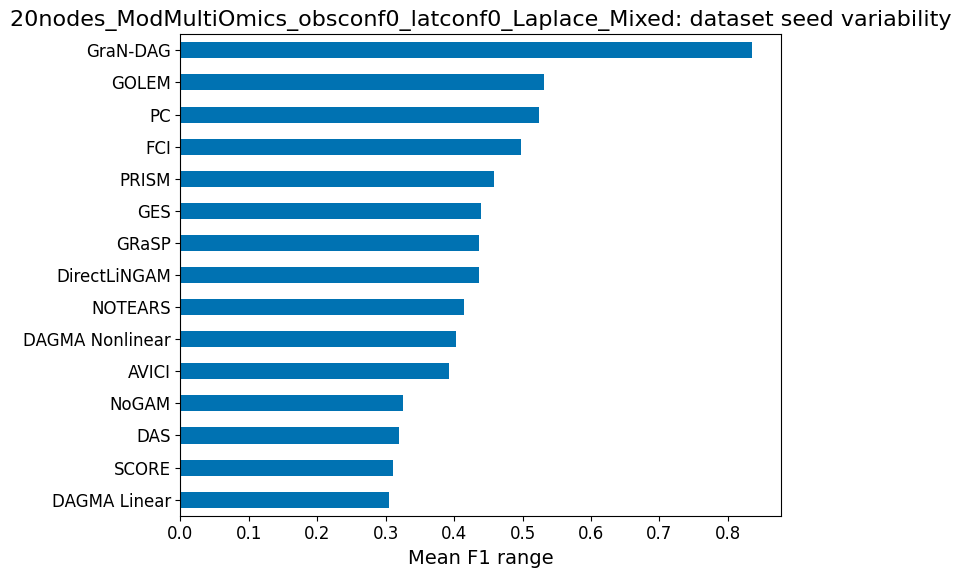

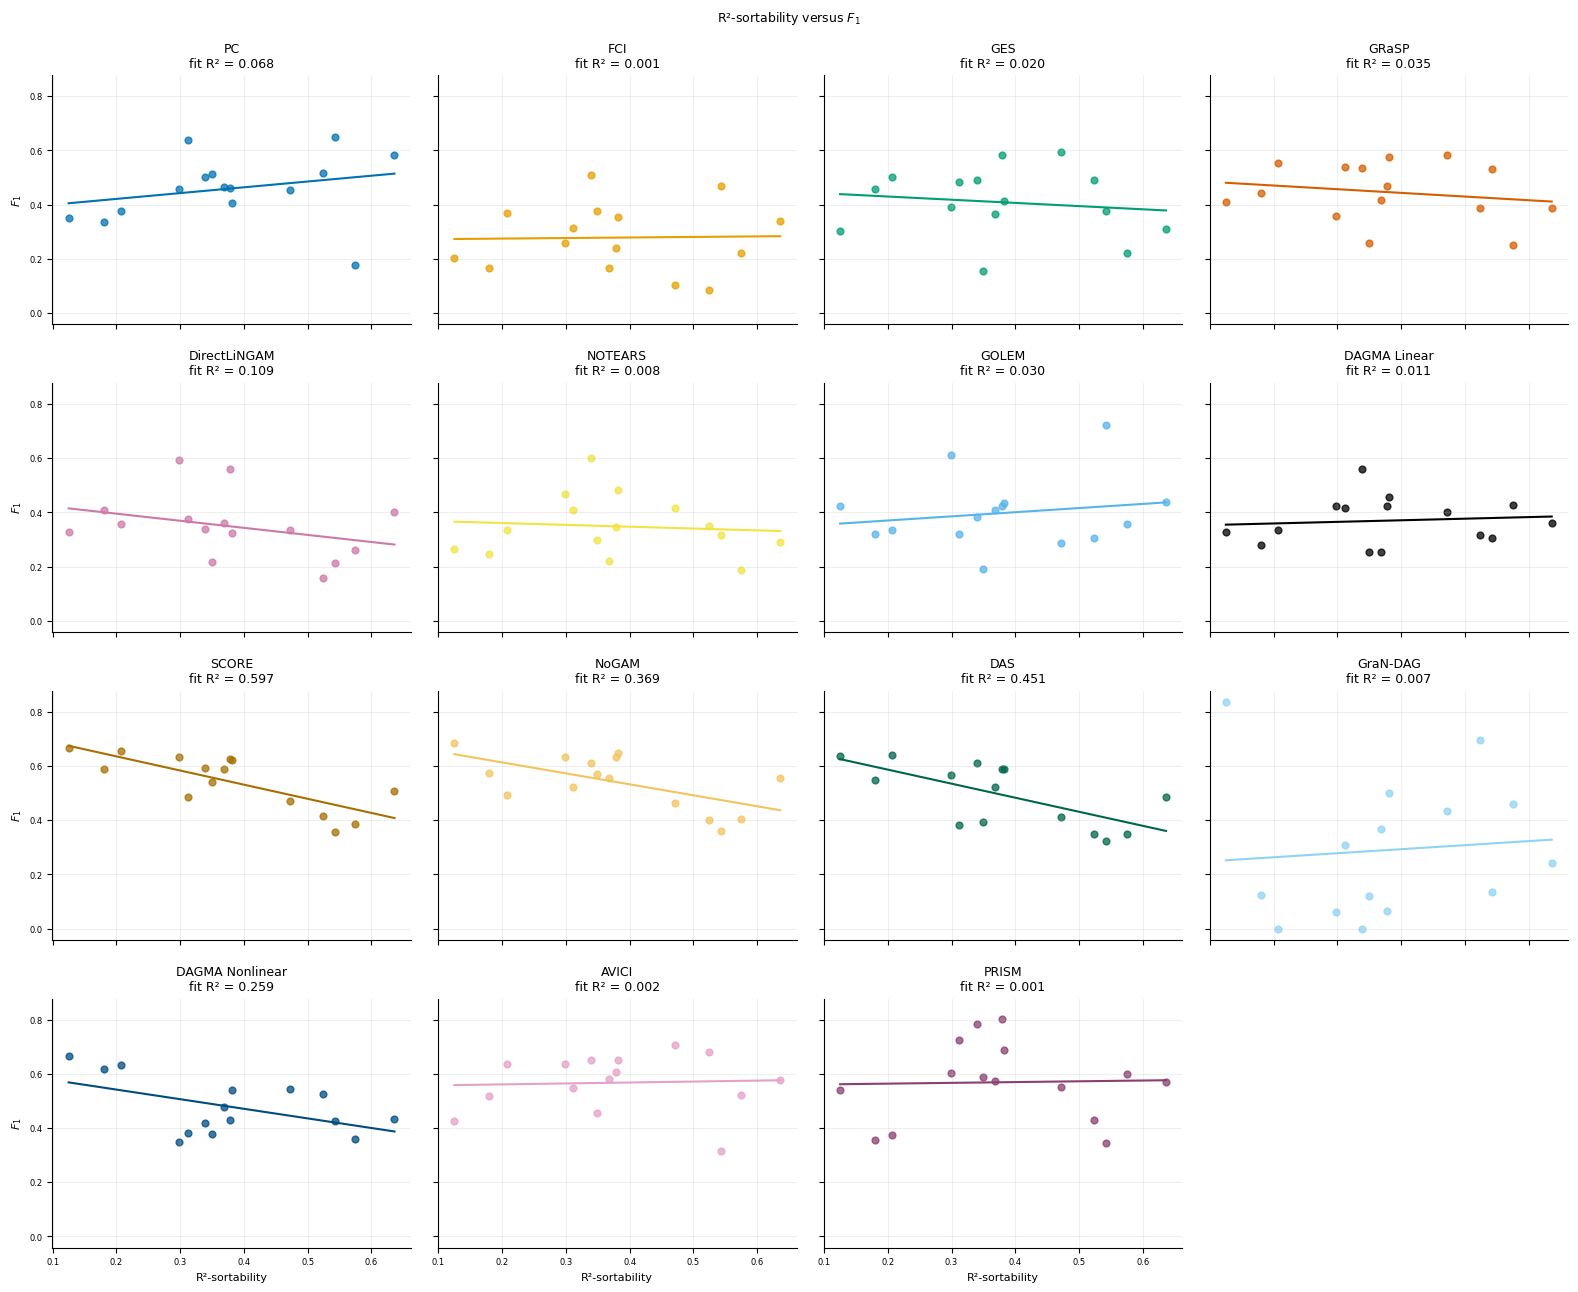

,dataset_seed,dataset,model,metric_value,completed_model_seeds,n_nodes,graph_type,obs_conf,lat_conf,noise,...,sample_path,varsortability,r2_sortability,n_paths,n_ordered_variance_paths,n_tied_variance_paths,n_ordered_r2_paths,n_tied_r2_paths,n_variables,n_observations
0,19,20nodes_ModMultiOmics_obsconf0_latconf0_Laplac...,AVICI,0.583333,5,20,ModMultiOmics,0,0,Laplace,...,datasets/tuned/20nodes_ModMultiOmics_obsconf0_...,0.50000,0.368421,38,19,0,14,0,20,2000
1,19,20nodes_ModMultiOmics_obsconf0_latconf0_Laplac...,DAGMA_Linear,0.255319,5,20,ModMultiOmics,0,0,Laplace,...,datasets/tuned/20nodes_ModMultiOmics_obsconf0_...,0.50000,0.368421,38,19,0,14,0,20,2000
2,19,20nodes_ModMultiOmics_obsconf0_latconf0_Laplac...,DAGMA_Nonlinear,0.478133,5,20,ModMultiOmics,0,0,Laplace,...,datasets/tuned/20nodes_ModMultiOmics_obsconf0_...,0.50000,0.368421,38,19,0,14,0,20,2000
3,19,20nodes_ModMultiOmics_obsconf0_latconf0_Laplac...,DAS,0.524590,5,20,ModMultiOmics,0,0,Laplace,...,datasets/tuned/20nodes_ModMultiOmics_obsconf0_...,0.50000,0.368421,38,19,0,14,0,20,2000
4,19,20nodes_ModMultiOmics_obsconf0_latconf0_Laplac...,DirectLiNGAM,0.360000,5,20,ModMultiOmics,0,0,Laplace,...,datasets/tuned/20nodes_ModMultiOmics_obsconf0_...,0.50000,0.368421,38,19,0,14,0,20,2000
5,19,20nodes_ModMultiOmics_obsconf0_latconf0_Laplac...,FCI,0.167056,5,20,ModMultiOmics,0,0,Laplace,...,datasets/tuned/20nodes_ModMultiOmics_obsconf0_...,0.50000,0.368421,38,19,0,14,0,20,2000
6,19,20nodes_ModMultiOmics_obsconf0_latconf0_Laplac...,GES,0.363636,5,20,ModMultiOmics,0,0,Laplace,...,datasets/tuned/20nodes_ModMultiOmics_obsconf0_...,0.50000,0.368421,38,19,0,14,0,20,2000
7,19,20nodes_ModMultiOmics_obsconf0_latconf0_Laplac...,GOLEM,0.409091,5,20,ModMultiOmics,0,0,Laplace,...,datasets/tuned/20nodes_ModMultiOmics_obsconf0_...,0.50000,0.368421,38,19,0,14,0,20,2000
8,19,20nodes_ModMultiOmics_obsconf0_latconf0_Laplac...,GRaSP,0.415003,5,20,ModMultiOmics,0,0,Laplace,...,datasets/tuned/20nodes_ModMultiOmics_obsconf0_...,0.50000,0.368421,38,19,0,14,0,20,2000
9,19,20nodes_ModMultiOmics_obsconf0_latconf0_Laplac...,GraNDAG,0.368421,5,20,ModMultiOmics,0,0,Laplace,...,datasets/tuned/20nodes_ModMultiOmics_obsconf0_...,0.50000,0.368421,38,19,0,14,0,20,2000


,dataset,dataset_seed,study,raw_variance_available,sample_path,varsortability,r2_sortability,n_paths,n_ordered_variance_paths,n_tied_variance_paths,n_ordered_r2_paths,n_tied_r2_paths,n_variables,n_observations
0,20nodes_ModMultiOmics_obsconf0_latconf0_Laplac...,19,tuned,True,datasets/tuned/20nodes_ModMultiOmics_obsconf0_...,0.500000,0.368421,38,19,0,14,0,20,2000
1,20nodes_ModMultiOmics_obsconf0_latconf0_Laplac...,47,tuned,True,datasets/tuned/20nodes_ModMultiOmics_obsconf0_...,0.611650,0.349515,103,63,0,36,0,20,2000
2,20nodes_ModMultiOmics_obsconf0_latconf0_Laplac...,50,tuned,True,datasets/tuned/20nodes_ModMultiOmics_obsconf0_...,0.636364,0.636364,88,56,0,56,0,20,2000
3,20nodes_ModMultiOmics_obsconf0_latconf0_Laplac...,52,tuned,True,datasets/tuned/20nodes_ModMultiOmics_obsconf0_...,0.125000,0.125000,80,10,0,10,0,20,2000
4,20nodes_ModMultiOmics_obsconf0_latconf0_Laplac...,71,tuned,True,datasets/tuned/20nodes_ModMultiOmics_obsconf0_...,0.553571,0.339286,56,31,0,19,0,20,2000
5,20nodes_ModMultiOmics_obsconf0_latconf0_Laplac...,75,tuned,True,datasets/tuned/20nodes_ModMultiOmics_obsconf0_...,0.415584,0.311688,77,32,0,24,0,20,2000
6,20nodes_ModMultiOmics_obsconf0_latconf0_Laplac...,77,tuned,True,datasets/tuned/20nodes_ModMultiOmics_obsconf0_...,0.434211,0.381579,76,33,0,29,0,20,2000
7,20nodes_ModMultiOmics_obsconf0_latconf0_Laplac...,102,tuned,True,datasets/tuned/20nodes_ModMultiOmics_obsconf0_...,0.547619,0.523810,42,23,0,22,0,20,2000
8,20nodes_ModMultiOmics_obsconf0_latconf0_Laplac...,125,tuned,True,datasets/tuned/20nodes_ModMultiOmics_obsconf0_...,0.200000,0.180000,50,10,0,9,0,20,2000
9,20nodes_ModMultiOmics_obsconf0_latconf0_Laplac...,158,tuned,True,datasets/tuned/20nodes_ModMultiOmics_obsconf0_...,0.660377,0.471698,53,35,0,25,0,20,2000


""


,model,n_datasets,pearson_r,fit_r_squared,slope,intercept,p_value,spearman_rho,spearman_p_value
0,AVICI,15,0.048424,0.002345,0.034892,0.555036,0.863929,0.151921,0.588854
1,DAGMA_Linear,15,0.102774,0.010563,0.058778,0.347455,0.715501,0.126899,0.652228
2,DAGMA_Nonlinear,15,-0.508850,0.258929,-0.354926,0.613799,0.052731,-0.282143,0.308284
3,DAS,15,-0.671799,0.451314,-0.519217,0.691181,0.006089,-0.632143,0.011458
4,DirectLiNGAM,15,-0.330603,0.109298,-0.261669,0.447696,0.228763,-0.392857,0.147467
5,FCI,15,0.023877,0.000570,0.020323,0.270028,0.932689,0.000000,1.000000
6,GES,15,-0.140276,0.019677,-0.118016,0.453183,0.618039,-0.121429,0.666401
7,GOLEM,15,0.174545,0.030466,0.153244,0.339543,0.533830,0.160858,0.566846
8,GRaSP,15,-0.186590,0.034816,-0.135834,0.497417,0.505505,-0.135714,0.629620
9,GraNDAG,15,0.086435,0.007471,0.149090,0.233620,0.759381,0.309205,0.262112


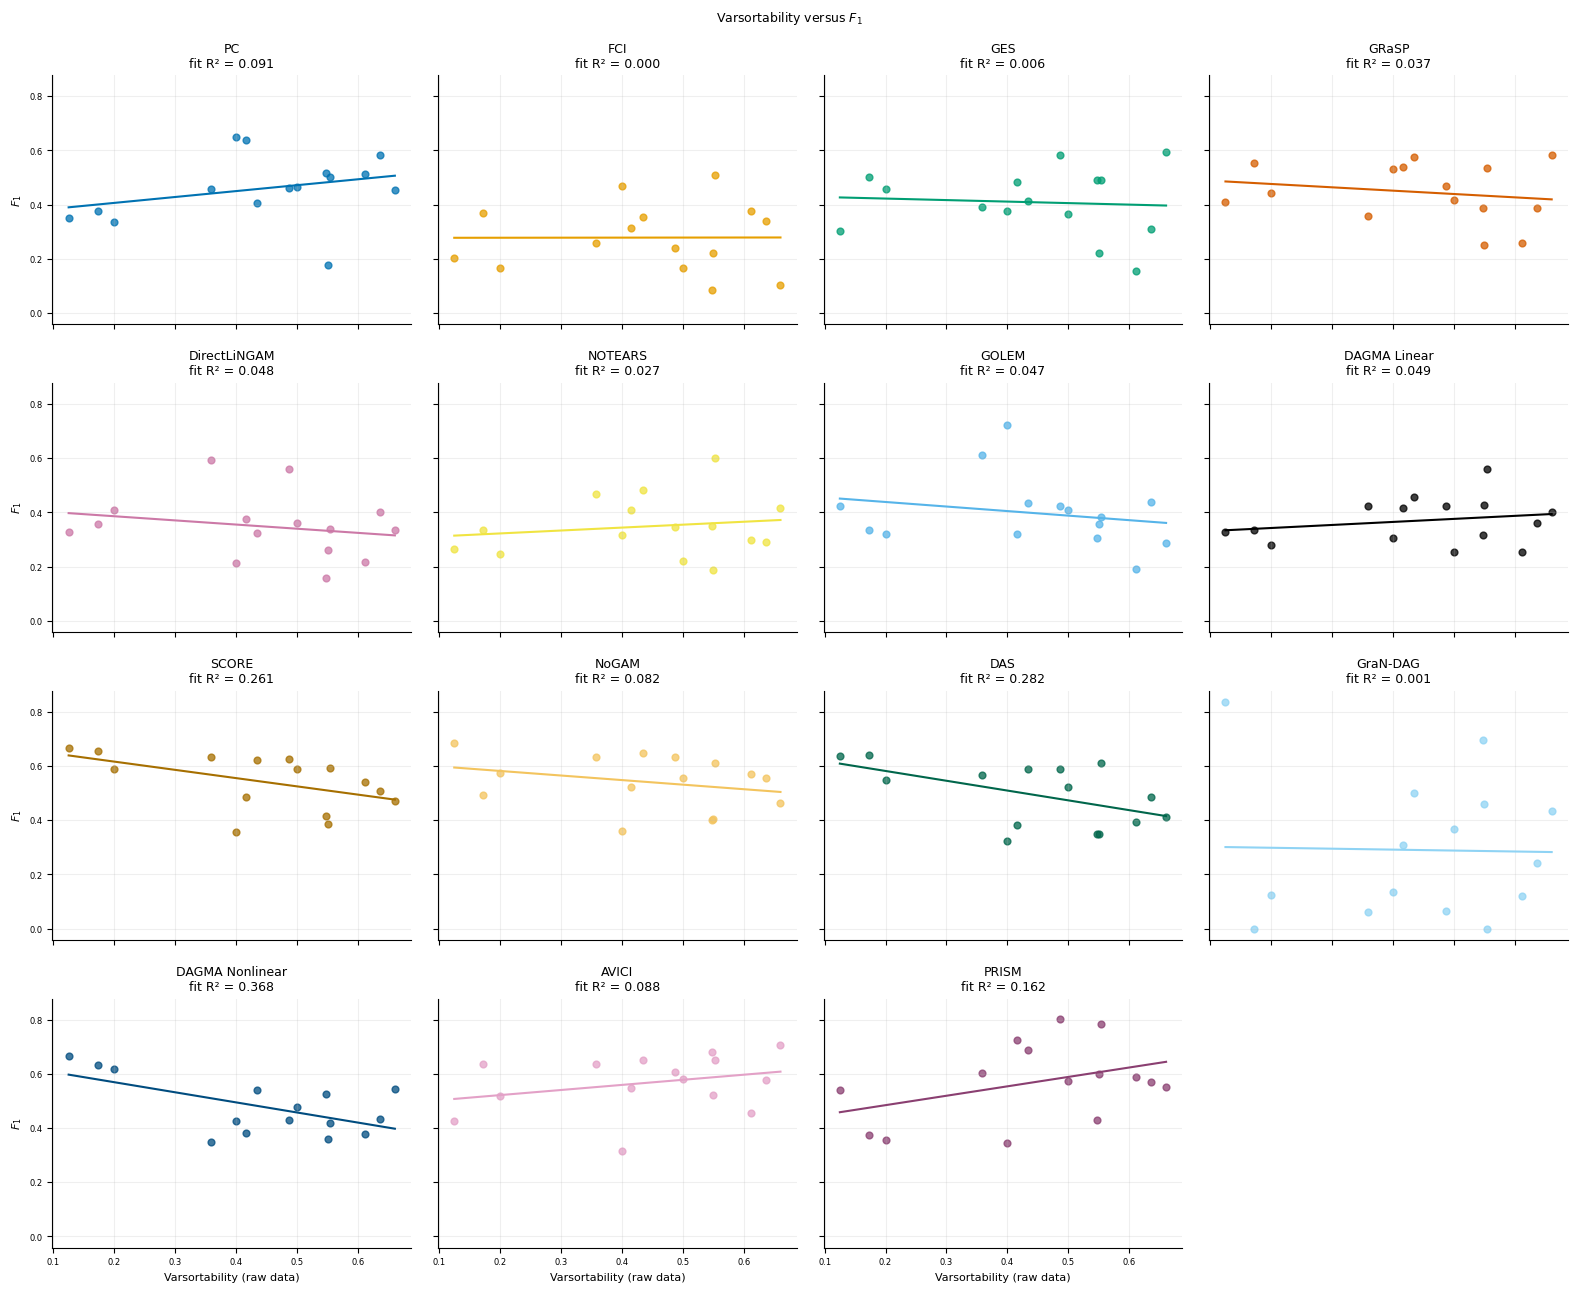

,dataset_seed,dataset,model,metric_value,completed_model_seeds,n_nodes,graph_type,obs_conf,lat_conf,noise,...,sample_path,varsortability,r2_sortability,n_paths,n_ordered_variance_paths,n_tied_variance_paths,n_ordered_r2_paths,n_tied_r2_paths,n_variables,n_observations
0,19,20nodes_ModMultiOmics_obsconf0_latconf0_Laplac...,AVICI,0.583333,5,20,ModMultiOmics,0,0,Laplace,...,datasets/tuned/20nodes_ModMultiOmics_obsconf0_...,0.50000,0.368421,38,19,0,14,0,20,2000
1,19,20nodes_ModMultiOmics_obsconf0_latconf0_Laplac...,DAGMA_Linear,0.255319,5,20,ModMultiOmics,0,0,Laplace,...,datasets/tuned/20nodes_ModMultiOmics_obsconf0_...,0.50000,0.368421,38,19,0,14,0,20,2000
2,19,20nodes_ModMultiOmics_obsconf0_latconf0_Laplac...,DAGMA_Nonlinear,0.478133,5,20,ModMultiOmics,0,0,Laplace,...,datasets/tuned/20nodes_ModMultiOmics_obsconf0_...,0.50000,0.368421,38,19,0,14,0,20,2000
3,19,20nodes_ModMultiOmics_obsconf0_latconf0_Laplac...,DAS,0.524590,5,20,ModMultiOmics,0,0,Laplace,...,datasets/tuned/20nodes_ModMultiOmics_obsconf0_...,0.50000,0.368421,38,19,0,14,0,20,2000
4,19,20nodes_ModMultiOmics_obsconf0_latconf0_Laplac...,DirectLiNGAM,0.360000,5,20,ModMultiOmics,0,0,Laplace,...,datasets/tuned/20nodes_ModMultiOmics_obsconf0_...,0.50000,0.368421,38,19,0,14,0,20,2000
5,19,20nodes_ModMultiOmics_obsconf0_latconf0_Laplac...,FCI,0.167056,5,20,ModMultiOmics,0,0,Laplace,...,datasets/tuned/20nodes_ModMultiOmics_obsconf0_...,0.50000,0.368421,38,19,0,14,0,20,2000
6,19,20nodes_ModMultiOmics_obsconf0_latconf0_Laplac...,GES,0.363636,5,20,ModMultiOmics,0,0,Laplace,...,datasets/tuned/20nodes_ModMultiOmics_obsconf0_...,0.50000,0.368421,38,19,0,14,0,20,2000
7,19,20nodes_ModMultiOmics_obsconf0_latconf0_Laplac...,GOLEM,0.409091,5,20,ModMultiOmics,0,0,Laplace,...,datasets/tuned/20nodes_ModMultiOmics_obsconf0_...,0.50000,0.368421,38,19,0,14,0,20,2000
8,19,20nodes_ModMultiOmics_obsconf0_latconf0_Laplac...,GRaSP,0.415003,5,20,ModMultiOmics,0,0,Laplace,...,datasets/tuned/20nodes_ModMultiOmics_obsconf0_...,0.50000,0.368421,38,19,0,14,0,20,2000
9,19,20nodes_ModMultiOmics_obsconf0_latconf0_Laplac...,GraNDAG,0.368421,5,20,ModMultiOmics,0,0,Laplace,...,datasets/tuned/20nodes_ModMultiOmics_obsconf0_...,0.50000,0.368421,38,19,0,14,0,20,2000


,dataset,dataset_seed,study,raw_variance_available,sample_path,varsortability,r2_sortability,n_paths,n_ordered_variance_paths,n_tied_variance_paths,n_ordered_r2_paths,n_tied_r2_paths,n_variables,n_observations
0,20nodes_ModMultiOmics_obsconf0_latconf0_Laplac...,19,tuned,True,datasets/tuned/20nodes_ModMultiOmics_obsconf0_...,0.500000,0.368421,38,19,0,14,0,20,2000
1,20nodes_ModMultiOmics_obsconf0_latconf0_Laplac...,47,tuned,True,datasets/tuned/20nodes_ModMultiOmics_obsconf0_...,0.611650,0.349515,103,63,0,36,0,20,2000
2,20nodes_ModMultiOmics_obsconf0_latconf0_Laplac...,50,tuned,True,datasets/tuned/20nodes_ModMultiOmics_obsconf0_...,0.636364,0.636364,88,56,0,56,0,20,2000
3,20nodes_ModMultiOmics_obsconf0_latconf0_Laplac...,52,tuned,True,datasets/tuned/20nodes_ModMultiOmics_obsconf0_...,0.125000,0.125000,80,10,0,10,0,20,2000
4,20nodes_ModMultiOmics_obsconf0_latconf0_Laplac...,71,tuned,True,datasets/tuned/20nodes_ModMultiOmics_obsconf0_...,0.553571,0.339286,56,31,0,19,0,20,2000
5,20nodes_ModMultiOmics_obsconf0_latconf0_Laplac...,75,tuned,True,datasets/tuned/20nodes_ModMultiOmics_obsconf0_...,0.415584,0.311688,77,32,0,24,0,20,2000
6,20nodes_ModMultiOmics_obsconf0_latconf0_Laplac...,77,tuned,True,datasets/tuned/20nodes_ModMultiOmics_obsconf0_...,0.434211,0.381579,76,33,0,29,0,20,2000
7,20nodes_ModMultiOmics_obsconf0_latconf0_Laplac...,102,tuned,True,datasets/tuned/20nodes_ModMultiOmics_obsconf0_...,0.547619,0.523810,42,23,0,22,0,20,2000
8,20nodes_ModMultiOmics_obsconf0_latconf0_Laplac...,125,tuned,True,datasets/tuned/20nodes_ModMultiOmics_obsconf0_...,0.200000,0.180000,50,10,0,9,0,20,2000
9,20nodes_ModMultiOmics_obsconf0_latconf0_Laplac...,158,tuned,True,datasets/tuned/20nodes_ModMultiOmics_obsconf0_...,0.660377,0.471698,53,35,0,25,0,20,2000


""


,model,n_datasets,pearson_r,fit_r_squared,slope,intercept,p_value,spearman_rho,spearman_p_value
0,AVICI,15,0.296467,0.087893,0.188485,0.484689,0.283289,0.336014,0.220773
1,DAGMA_Linear,15,0.222321,0.049427,0.112188,0.320000,0.425806,0.128686,0.647620
2,DAGMA_Nonlinear,15,-0.606648,0.368022,-0.373355,0.644745,0.016493,-0.332143,0.226472
3,DAS,15,-0.531190,0.282163,-0.362240,0.654888,0.041591,-0.407143,0.132013
4,DirectLiNGAM,15,-0.220118,0.048452,-0.153723,0.416619,0.430524,-0.221429,0.427714
5,FCI,15,0.002802,0.000008,0.002104,0.276802,0.992093,-0.007143,0.979844
6,GES,15,-0.075330,0.005675,-0.055919,0.433220,0.789609,-0.010714,0.969770
7,GOLEM,15,-0.217043,0.047108,-0.168135,0.472220,0.437153,-0.312779,0.256346
8,GRaSP,15,-0.192618,0.037102,-0.123724,0.500763,0.491598,-0.117857,0.675712
9,GraNDAG,15,-0.022669,0.000514,-0.034501,0.305464,0.936087,0.078642,0.780563


,model,mean,std,size
0,AVICI,0.593813,0.101639,15
1,DAGMA_Linear,0.309639,0.124504,15
2,DAGMA_Nonlinear,0.370233,0.047428,15
3,DAS,0.456322,0.121719,15
4,DirectLiNGAM,0.341419,0.100656,15
5,FCI,0.177679,0.098001,15
6,GES,0.444390,0.138657,15
7,GOLEM,0.302832,0.129063,15
8,GRaSP,0.445899,0.108043,15
9,GraNDAG,0.125044,0.143791,15


,model,mean,std,size
0,AVICI,20.200000,6.002380,15
1,DAGMA_Linear,24.533333,4.867775,15
2,DAGMA_Nonlinear,24.053333,3.013746,15
3,DAS,29.600000,8.122280,15
4,DirectLiNGAM,33.800000,8.213230,15
5,FCI,29.933333,7.045431,15
6,GES,28.866667,7.170044,15
7,GOLEM,30.066667,7.343283,15
8,GRaSP,25.613333,5.099281,15
9,GraNDAG,26.400000,3.018988,15


,model,mean,std,size
0,AVICI,0.612618,0.115018,15
1,DAGMA_Linear,0.395860,0.140163,15
2,DAGMA_Nonlinear,0.441193,0.068834,15
3,DAS,0.396536,0.122997,15
4,DirectLiNGAM,0.294964,0.107722,15
5,FCI,0.564841,0.277706,15
6,GES,0.433327,0.144225,15
7,GOLEM,0.335618,0.155443,15
8,GRaSP,0.542809,0.120329,15
9,GraNDAG,0.601282,0.406593,15


,model,mean,std,size
0,AVICI,0.586767,0.112516,15
1,DAGMA_Linear,0.259093,0.117177,15
2,DAGMA_Nonlinear,0.324047,0.051355,15
3,DAS,0.544551,0.121144,15
4,DirectLiNGAM,0.415284,0.108655,15
5,FCI,0.107223,0.062055,15
6,GES,0.463884,0.147200,15
7,GOLEM,0.286532,0.130384,15
8,GRaSP,0.382422,0.104785,15
9,GraNDAG,0.076696,0.101633,15


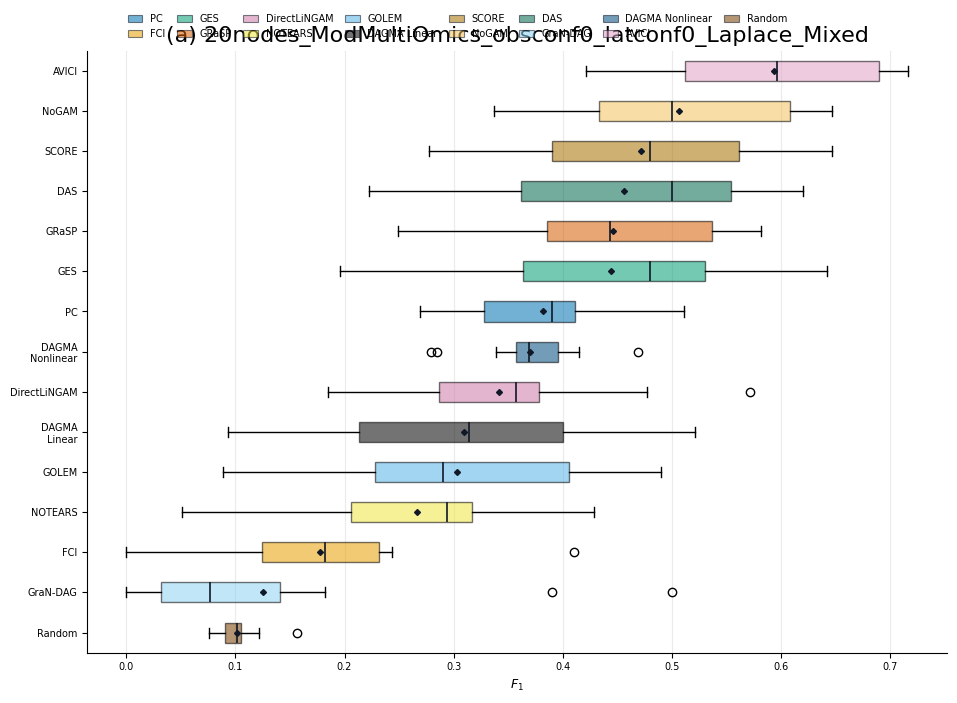

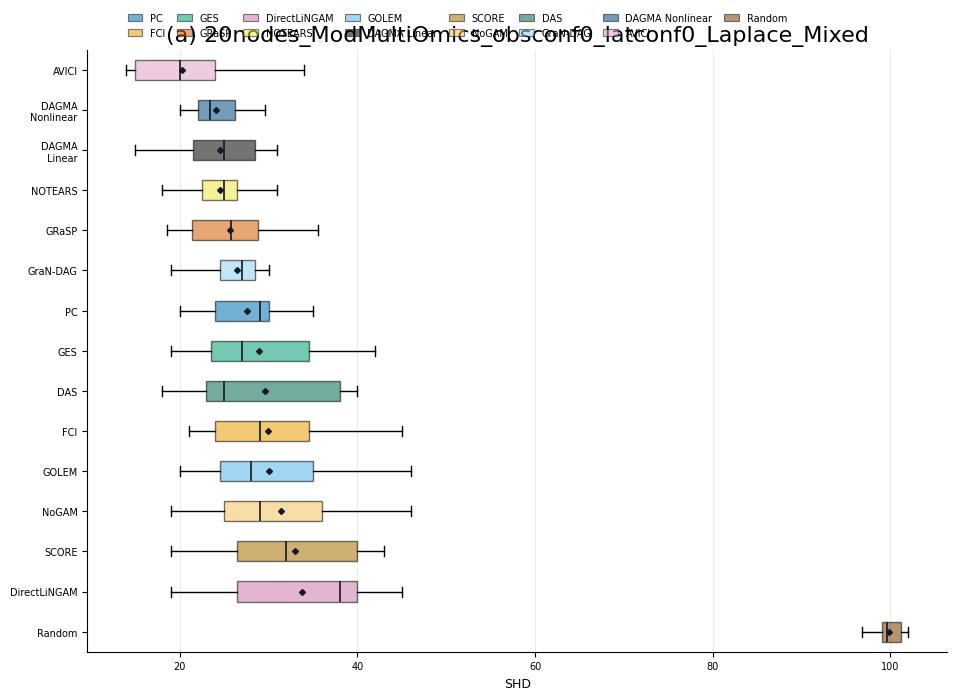

,dataset_seed,model,f1_range
0,19,AVICI,0.000000
1,19,DAGMA_Linear,0.000000
2,19,DAGMA_Nonlinear,0.180389
3,19,DAS,0.000000
4,19,DirectLiNGAM,0.000000
5,19,FCI,0.000000
6,19,GES,0.000000
7,19,GOLEM,0.000000
8,19,GRaSP,0.265457
9,19,GraNDAG,0.000000


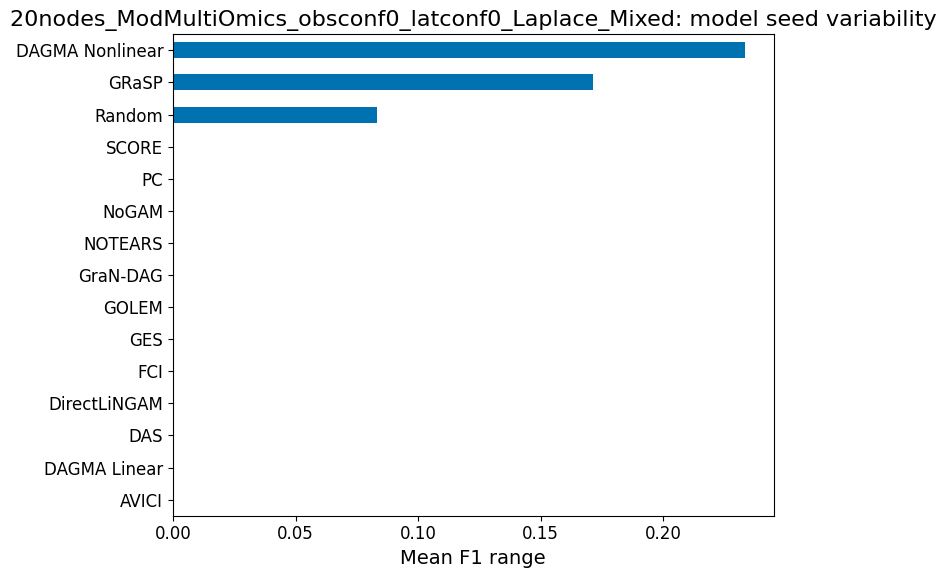

,model_seed,model,f1_range
0,0,AVICI,0.295929
1,0,DAGMA_Linear,0.428716
2,0,DAGMA_Nonlinear,0.269928
3,0,DAS,0.398467
4,0,DirectLiNGAM,0.386813
5,0,FCI,0.410256
6,0,GES,0.446779
7,0,GOLEM,0.400907
8,0,GRaSP,0.430643
9,0,GraNDAG,0.500000


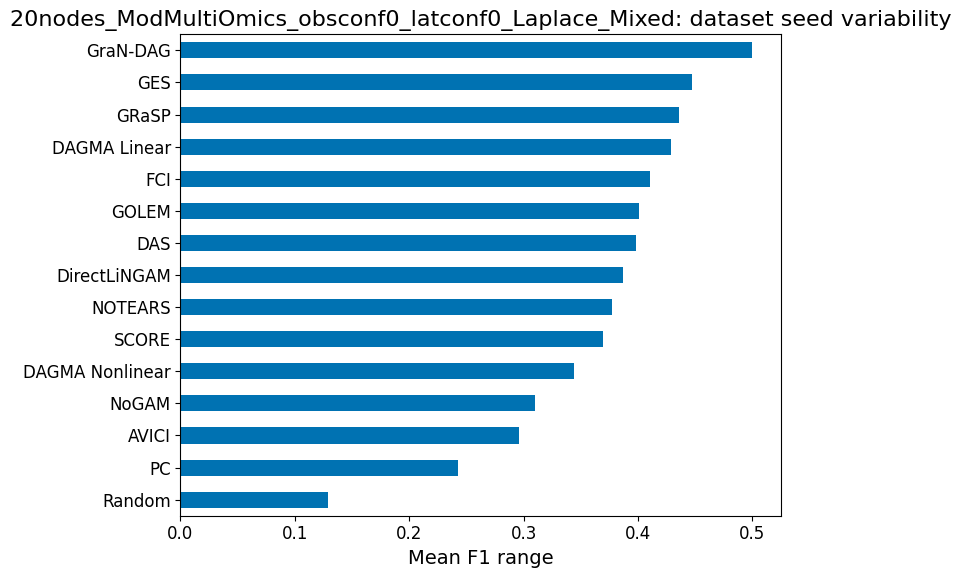

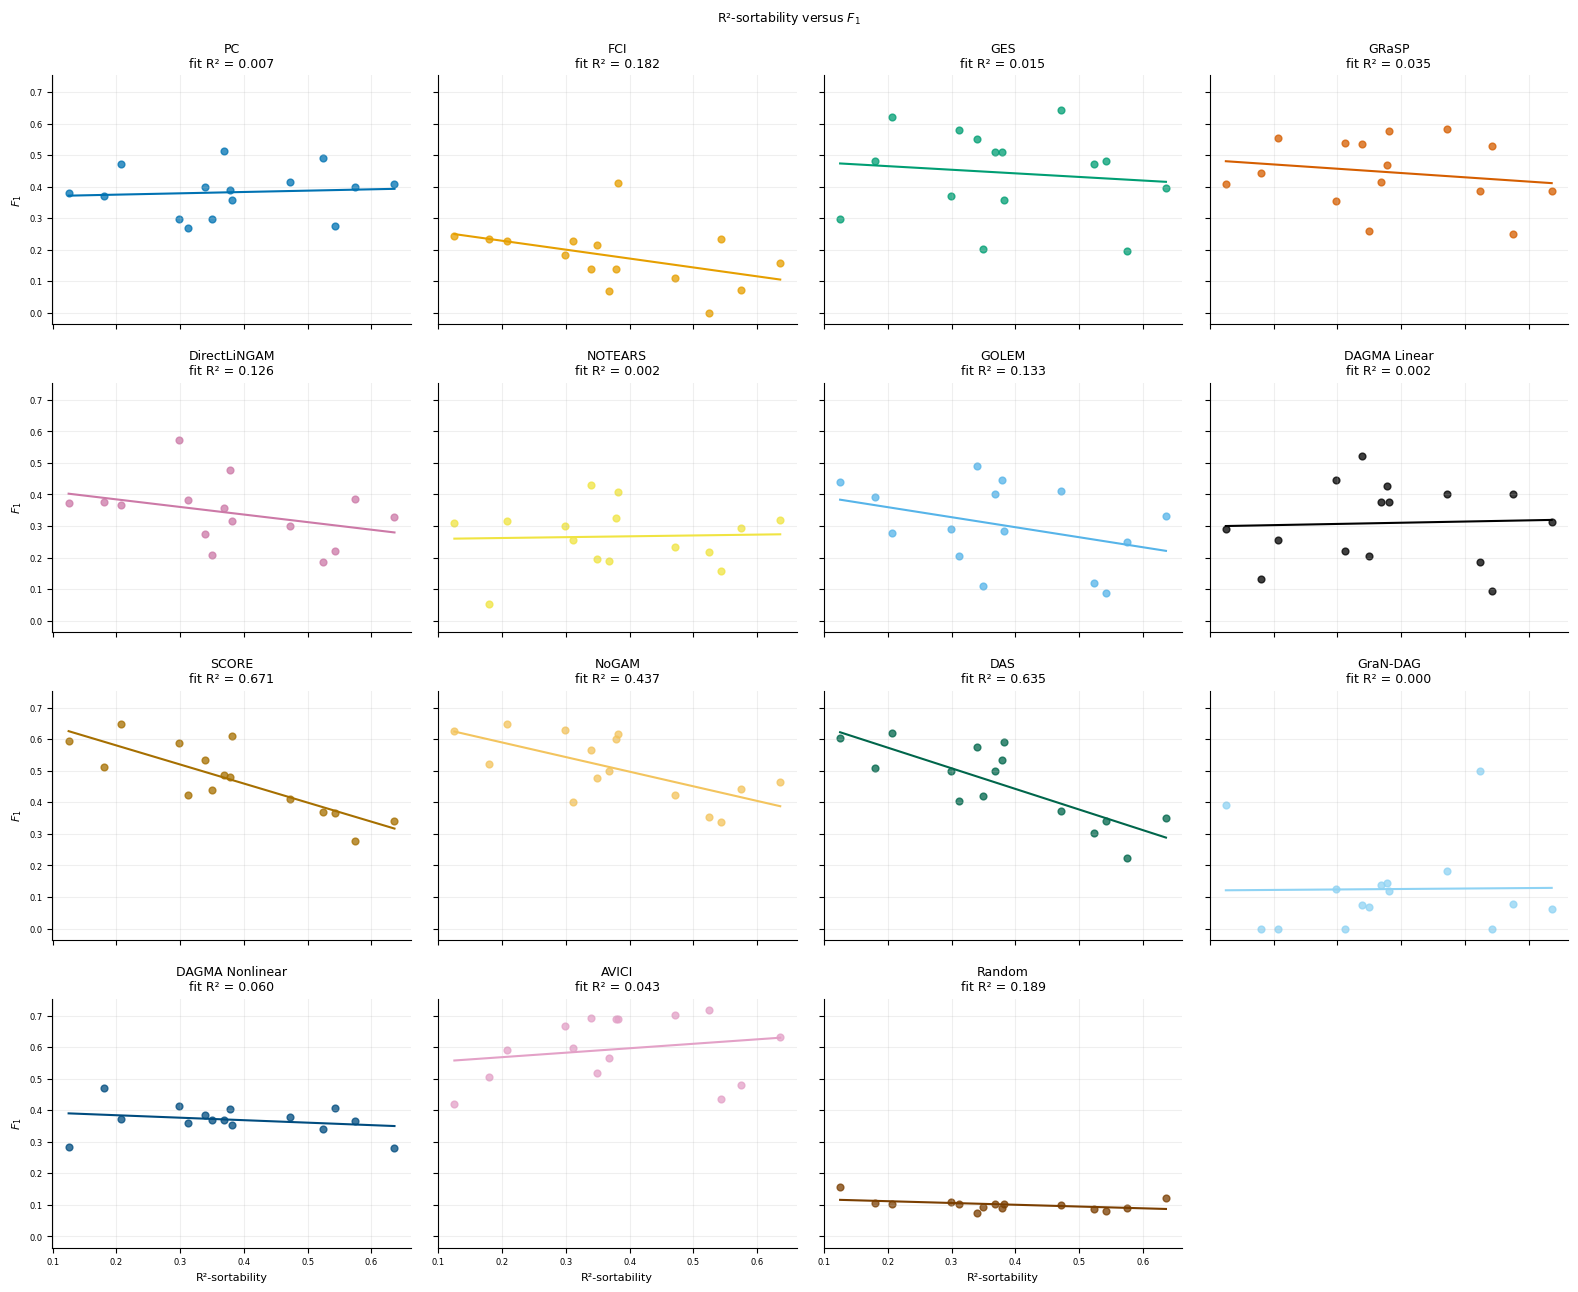

,dataset_seed,dataset,model,metric_value,completed_model_seeds,n_nodes,graph_type,obs_conf,lat_conf,noise,...,sample_path,varsortability,r2_sortability,n_paths,n_ordered_variance_paths,n_tied_variance_paths,n_ordered_r2_paths,n_tied_r2_paths,n_variables,n_observations
0,19,20nodes_ModMultiOmics_obsconf0_latconf0_Laplac...,AVICI,0.566038,5,20,ModMultiOmics,0,0,Laplace,...,datasets/tuned/20nodes_ModMultiOmics_obsconf0_...,0.50000,0.368421,38,19,0,14,0,20,2000
1,19,20nodes_ModMultiOmics_obsconf0_latconf0_Laplac...,DAGMA_Linear,0.375000,5,20,ModMultiOmics,0,0,Laplace,...,datasets/tuned/20nodes_ModMultiOmics_obsconf0_...,0.50000,0.368421,38,19,0,14,0,20,2000
2,19,20nodes_ModMultiOmics_obsconf0_latconf0_Laplac...,DAGMA_Nonlinear,0.368832,5,20,ModMultiOmics,0,0,Laplace,...,datasets/tuned/20nodes_ModMultiOmics_obsconf0_...,0.50000,0.368421,38,19,0,14,0,20,2000
3,19,20nodes_ModMultiOmics_obsconf0_latconf0_Laplac...,DAS,0.500000,5,20,ModMultiOmics,0,0,Laplace,...,datasets/tuned/20nodes_ModMultiOmics_obsconf0_...,0.50000,0.368421,38,19,0,14,0,20,2000
4,19,20nodes_ModMultiOmics_obsconf0_latconf0_Laplac...,DirectLiNGAM,0.357143,5,20,ModMultiOmics,0,0,Laplace,...,datasets/tuned/20nodes_ModMultiOmics_obsconf0_...,0.50000,0.368421,38,19,0,14,0,20,2000
5,19,20nodes_ModMultiOmics_obsconf0_latconf0_Laplac...,FCI,0.068966,5,20,ModMultiOmics,0,0,Laplace,...,datasets/tuned/20nodes_ModMultiOmics_obsconf0_...,0.50000,0.368421,38,19,0,14,0,20,2000
6,19,20nodes_ModMultiOmics_obsconf0_latconf0_Laplac...,GES,0.509804,5,20,ModMultiOmics,0,0,Laplace,...,datasets/tuned/20nodes_ModMultiOmics_obsconf0_...,0.50000,0.368421,38,19,0,14,0,20,2000
7,19,20nodes_ModMultiOmics_obsconf0_latconf0_Laplac...,GOLEM,0.400000,5,20,ModMultiOmics,0,0,Laplace,...,datasets/tuned/20nodes_ModMultiOmics_obsconf0_...,0.50000,0.368421,38,19,0,14,0,20,2000
8,19,20nodes_ModMultiOmics_obsconf0_latconf0_Laplac...,GRaSP,0.415003,5,20,ModMultiOmics,0,0,Laplace,...,datasets/tuned/20nodes_ModMultiOmics_obsconf0_...,0.50000,0.368421,38,19,0,14,0,20,2000
9,19,20nodes_ModMultiOmics_obsconf0_latconf0_Laplac...,GraNDAG,0.137931,5,20,ModMultiOmics,0,0,Laplace,...,datasets/tuned/20nodes_ModMultiOmics_obsconf0_...,0.50000,0.368421,38,19,0,14,0,20,2000


,dataset,dataset_seed,study,raw_variance_available,sample_path,varsortability,r2_sortability,n_paths,n_ordered_variance_paths,n_tied_variance_paths,n_ordered_r2_paths,n_tied_r2_paths,n_variables,n_observations
0,20nodes_ModMultiOmics_obsconf0_latconf0_Laplac...,19,tuned,True,datasets/tuned/20nodes_ModMultiOmics_obsconf0_...,0.500000,0.368421,38,19,0,14,0,20,2000
1,20nodes_ModMultiOmics_obsconf0_latconf0_Laplac...,47,tuned,True,datasets/tuned/20nodes_ModMultiOmics_obsconf0_...,0.611650,0.349515,103,63,0,36,0,20,2000
2,20nodes_ModMultiOmics_obsconf0_latconf0_Laplac...,50,tuned,True,datasets/tuned/20nodes_ModMultiOmics_obsconf0_...,0.636364,0.636364,88,56,0,56,0,20,2000
3,20nodes_ModMultiOmics_obsconf0_latconf0_Laplac...,52,tuned,True,datasets/tuned/20nodes_ModMultiOmics_obsconf0_...,0.125000,0.125000,80,10,0,10,0,20,2000
4,20nodes_ModMultiOmics_obsconf0_latconf0_Laplac...,71,tuned,True,datasets/tuned/20nodes_ModMultiOmics_obsconf0_...,0.553571,0.339286,56,31,0,19,0,20,2000
5,20nodes_ModMultiOmics_obsconf0_latconf0_Laplac...,75,tuned,True,datasets/tuned/20nodes_ModMultiOmics_obsconf0_...,0.415584,0.311688,77,32,0,24,0,20,2000
6,20nodes_ModMultiOmics_obsconf0_latconf0_Laplac...,77,tuned,True,datasets/tuned/20nodes_ModMultiOmics_obsconf0_...,0.434211,0.381579,76,33,0,29,0,20,2000
7,20nodes_ModMultiOmics_obsconf0_latconf0_Laplac...,102,tuned,True,datasets/tuned/20nodes_ModMultiOmics_obsconf0_...,0.547619,0.523810,42,23,0,22,0,20,2000
8,20nodes_ModMultiOmics_obsconf0_latconf0_Laplac...,125,tuned,True,datasets/tuned/20nodes_ModMultiOmics_obsconf0_...,0.200000,0.180000,50,10,0,9,0,20,2000
9,20nodes_ModMultiOmics_obsconf0_latconf0_Laplac...,158,tuned,True,datasets/tuned/20nodes_ModMultiOmics_obsconf0_...,0.660377,0.471698,53,35,0,25,0,20,2000


""


,model,n_datasets,pearson_r,fit_r_squared,slope,intercept,p_value,spearman_rho,spearman_p_value
0,AVICI,15,0.206250,0.042539,0.141247,0.540243,0.460824,0.235714,0.397703
1,DAGMA_Linear,15,0.045194,0.002043,0.037913,0.295260,0.872935,0.048257,0.864394
2,DAGMA_Nonlinear,15,-0.245838,0.060436,-0.078561,0.400028,0.377133,-0.285714,0.301936
3,DAS,15,-0.796614,0.634594,-0.653326,0.704107,0.000378,-0.746429,0.001391
4,DirectLiNGAM,15,-0.354396,0.125597,-0.240354,0.432577,0.194957,-0.357143,0.191275
5,FCI,15,-0.427073,0.182391,-0.282005,0.284634,0.112352,-0.454384,0.088842
6,GES,15,-0.121931,0.014867,-0.113915,0.487594,0.665095,-0.182143,0.515882
7,GOLEM,15,-0.364942,0.133182,-0.317359,0.423196,0.181066,-0.296429,0.283355
8,GRaSP,15,-0.186590,0.034816,-0.135834,0.497417,0.505505,-0.135714,0.629620
9,GraNDAG,15,0.015348,0.000236,0.014870,0.119405,0.956706,0.113518,0.687082


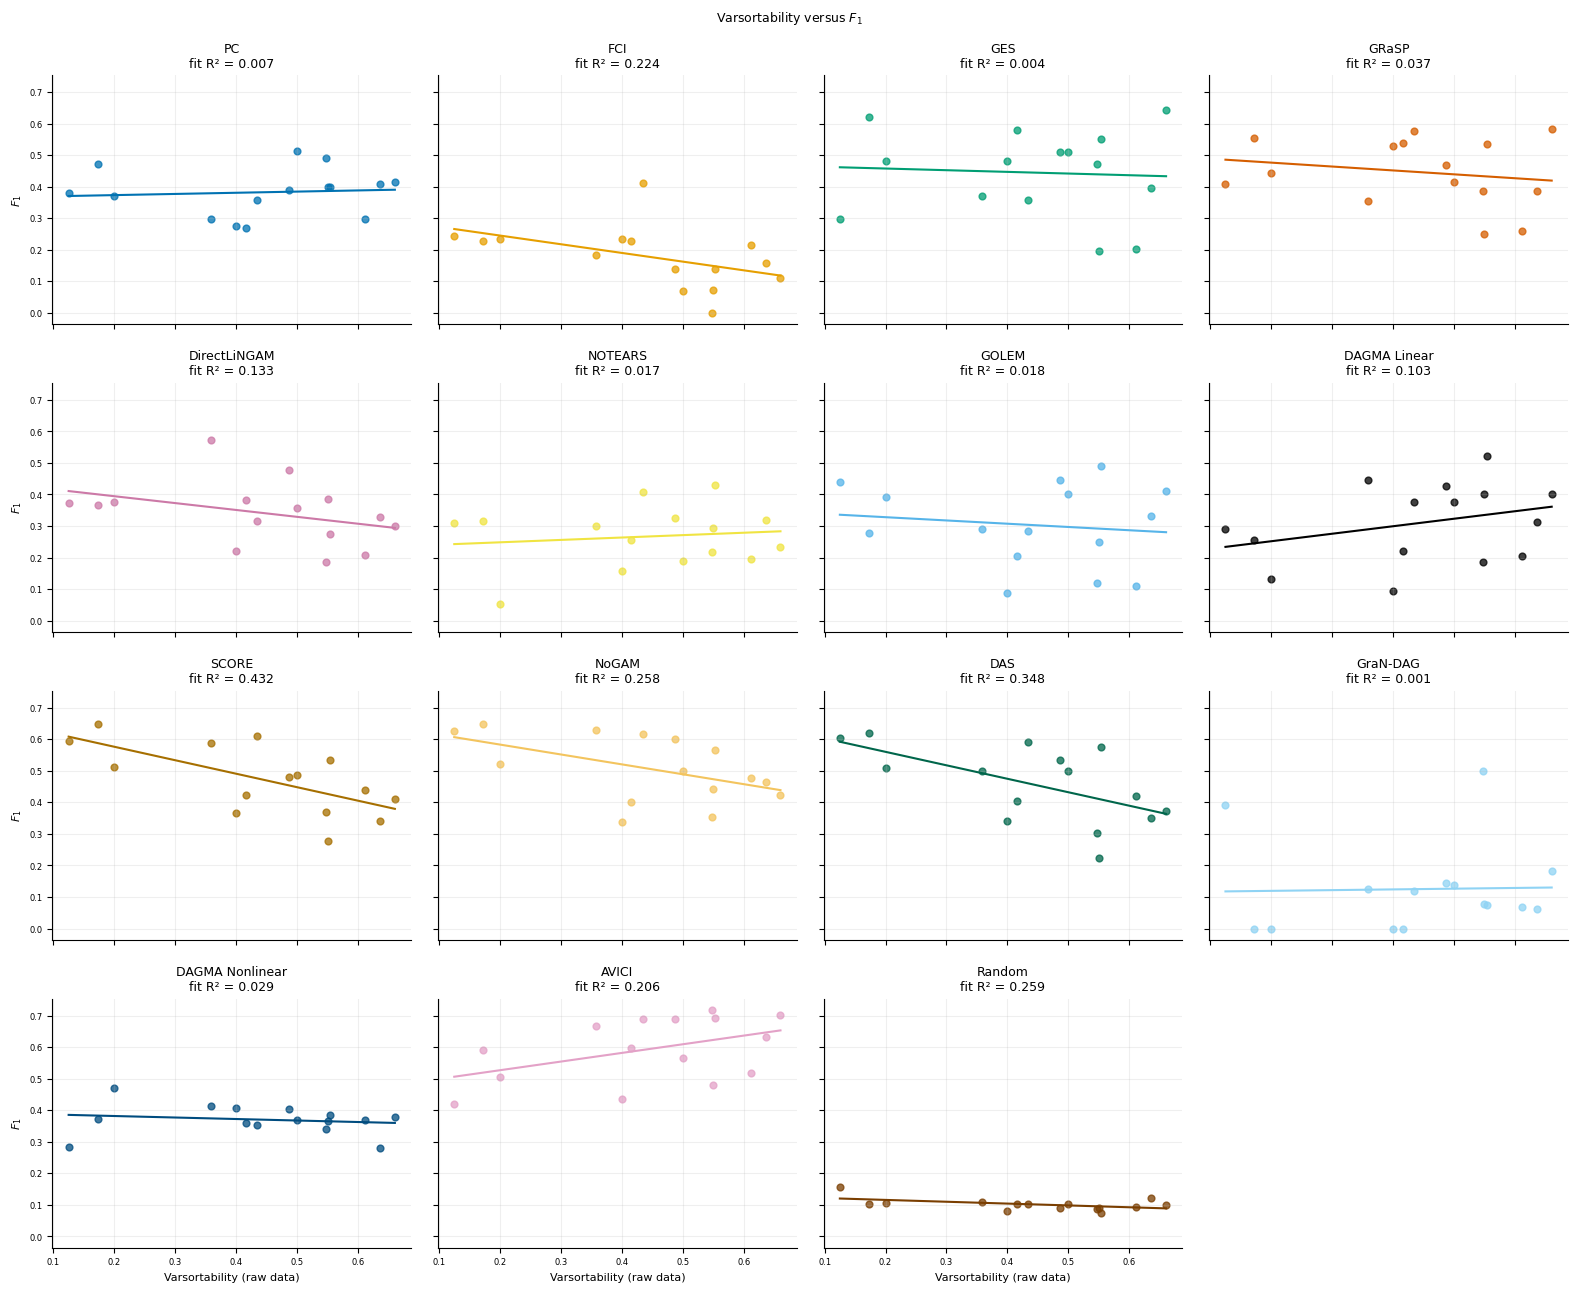

,dataset_seed,dataset,model,metric_value,completed_model_seeds,n_nodes,graph_type,obs_conf,lat_conf,noise,...,sample_path,varsortability,r2_sortability,n_paths,n_ordered_variance_paths,n_tied_variance_paths,n_ordered_r2_paths,n_tied_r2_paths,n_variables,n_observations
0,19,20nodes_ModMultiOmics_obsconf0_latconf0_Laplac...,AVICI,0.566038,5,20,ModMultiOmics,0,0,Laplace,...,datasets/tuned/20nodes_ModMultiOmics_obsconf0_...,0.50000,0.368421,38,19,0,14,0,20,2000
1,19,20nodes_ModMultiOmics_obsconf0_latconf0_Laplac...,DAGMA_Linear,0.375000,5,20,ModMultiOmics,0,0,Laplace,...,datasets/tuned/20nodes_ModMultiOmics_obsconf0_...,0.50000,0.368421,38,19,0,14,0,20,2000
2,19,20nodes_ModMultiOmics_obsconf0_latconf0_Laplac...,DAGMA_Nonlinear,0.368832,5,20,ModMultiOmics,0,0,Laplace,...,datasets/tuned/20nodes_ModMultiOmics_obsconf0_...,0.50000,0.368421,38,19,0,14,0,20,2000
3,19,20nodes_ModMultiOmics_obsconf0_latconf0_Laplac...,DAS,0.500000,5,20,ModMultiOmics,0,0,Laplace,...,datasets/tuned/20nodes_ModMultiOmics_obsconf0_...,0.50000,0.368421,38,19,0,14,0,20,2000
4,19,20nodes_ModMultiOmics_obsconf0_latconf0_Laplac...,DirectLiNGAM,0.357143,5,20,ModMultiOmics,0,0,Laplace,...,datasets/tuned/20nodes_ModMultiOmics_obsconf0_...,0.50000,0.368421,38,19,0,14,0,20,2000
5,19,20nodes_ModMultiOmics_obsconf0_latconf0_Laplac...,FCI,0.068966,5,20,ModMultiOmics,0,0,Laplace,...,datasets/tuned/20nodes_ModMultiOmics_obsconf0_...,0.50000,0.368421,38,19,0,14,0,20,2000
6,19,20nodes_ModMultiOmics_obsconf0_latconf0_Laplac...,GES,0.509804,5,20,ModMultiOmics,0,0,Laplace,...,datasets/tuned/20nodes_ModMultiOmics_obsconf0_...,0.50000,0.368421,38,19,0,14,0,20,2000
7,19,20nodes_ModMultiOmics_obsconf0_latconf0_Laplac...,GOLEM,0.400000,5,20,ModMultiOmics,0,0,Laplace,...,datasets/tuned/20nodes_ModMultiOmics_obsconf0_...,0.50000,0.368421,38,19,0,14,0,20,2000
8,19,20nodes_ModMultiOmics_obsconf0_latconf0_Laplac...,GRaSP,0.415003,5,20,ModMultiOmics,0,0,Laplace,...,datasets/tuned/20nodes_ModMultiOmics_obsconf0_...,0.50000,0.368421,38,19,0,14,0,20,2000
9,19,20nodes_ModMultiOmics_obsconf0_latconf0_Laplac...,GraNDAG,0.137931,5,20,ModMultiOmics,0,0,Laplace,...,datasets/tuned/20nodes_ModMultiOmics_obsconf0_...,0.50000,0.368421,38,19,0,14,0,20,2000


,dataset,dataset_seed,study,raw_variance_available,sample_path,varsortability,r2_sortability,n_paths,n_ordered_variance_paths,n_tied_variance_paths,n_ordered_r2_paths,n_tied_r2_paths,n_variables,n_observations
0,20nodes_ModMultiOmics_obsconf0_latconf0_Laplac...,19,tuned,True,datasets/tuned/20nodes_ModMultiOmics_obsconf0_...,0.500000,0.368421,38,19,0,14,0,20,2000
1,20nodes_ModMultiOmics_obsconf0_latconf0_Laplac...,47,tuned,True,datasets/tuned/20nodes_ModMultiOmics_obsconf0_...,0.611650,0.349515,103,63,0,36,0,20,2000
2,20nodes_ModMultiOmics_obsconf0_latconf0_Laplac...,50,tuned,True,datasets/tuned/20nodes_ModMultiOmics_obsconf0_...,0.636364,0.636364,88,56,0,56,0,20,2000
3,20nodes_ModMultiOmics_obsconf0_latconf0_Laplac...,52,tuned,True,datasets/tuned/20nodes_ModMultiOmics_obsconf0_...,0.125000,0.125000,80,10,0,10,0,20,2000
4,20nodes_ModMultiOmics_obsconf0_latconf0_Laplac...,71,tuned,True,datasets/tuned/20nodes_ModMultiOmics_obsconf0_...,0.553571,0.339286,56,31,0,19,0,20,2000
5,20nodes_ModMultiOmics_obsconf0_latconf0_Laplac...,75,tuned,True,datasets/tuned/20nodes_ModMultiOmics_obsconf0_...,0.415584,0.311688,77,32,0,24,0,20,2000
6,20nodes_ModMultiOmics_obsconf0_latconf0_Laplac...,77,tuned,True,datasets/tuned/20nodes_ModMultiOmics_obsconf0_...,0.434211,0.381579,76,33,0,29,0,20,2000
7,20nodes_ModMultiOmics_obsconf0_latconf0_Laplac...,102,tuned,True,datasets/tuned/20nodes_ModMultiOmics_obsconf0_...,0.547619,0.523810,42,23,0,22,0,20,2000
8,20nodes_ModMultiOmics_obsconf0_latconf0_Laplac...,125,tuned,True,datasets/tuned/20nodes_ModMultiOmics_obsconf0_...,0.200000,0.180000,50,10,0,9,0,20,2000
9,20nodes_ModMultiOmics_obsconf0_latconf0_Laplac...,158,tuned,True,datasets/tuned/20nodes_ModMultiOmics_obsconf0_...,0.660377,0.471698,53,35,0,25,0,20,2000


""


,model,n_datasets,pearson_r,fit_r_squared,slope,intercept,p_value,spearman_rho,spearman_p_value
0,AVICI,15,0.454111,0.206217,0.274399,0.472135,0.089058,0.471429,0.076070
1,DAGMA_Linear,15,0.321404,0.103300,0.237900,0.204146,0.242757,0.300268,0.276866
2,DAGMA_Nonlinear,15,-0.168889,0.028523,-0.047621,0.391349,0.547370,-0.217857,0.435393
3,DAS,15,-0.590209,0.348347,-0.427096,0.645710,0.020546,-0.539286,0.038022
4,DirectLiNGAM,15,-0.364480,0.132846,-0.218109,0.438136,0.181660,-0.450000,0.092357
5,FCI,15,-0.473059,0.223784,-0.275618,0.299897,0.074922,-0.633275,0.011266
6,GES,15,-0.064302,0.004135,-0.053006,0.467895,0.819904,0.010714,0.969770
7,GOLEM,15,-0.134883,0.018193,-0.103495,0.348725,0.631740,0.046429,0.869492
8,GRaSP,15,-0.192618,0.037102,-0.123724,0.500763,0.491598,-0.117857,0.675712
9,GraNDAG,15,0.026920,0.000725,0.023013,0.114839,0.924130,0.205414,0.462685


In [3]:
for study, frame in [("tuned", complete)]:
    frame = frame.loc[frame.dataset.eq('20nodes_ModMultiOmics_obsconf0_latconf0_Laplace_Mixed')].copy()
    values = sortability(frame, study)
    arms = (
        [("untuned", frame)]
        if study == "benchmark"
        else list(frame.groupby("arm", observed=True))
    )
    for arm, arm_frame in arms:
        for family, group in arm_frame.groupby("dataset", observed=True):
            family_output = output / study / "by_family" / family / arm
            family_output.mkdir(parents=True, exist_ok=True)
            data = th.visualization_data(group)
            # F1 and SHD, precision and recall retain dataset-level blocks.
            for metric in ("f1", "SHD", "precision", "recall"):
                blocks = (
                    group.loc[group.finished]
                    .groupby(["dataset_seed", "model"])[metric]
                    .mean()
                    .reset_index()
                )
                summary = (
                    blocks.groupby("model")[metric].agg(["mean", "std", "size"]).reset_index()
                )
                display(summary.head(20))
            for metric in ("f1", "SHD"):
                fig, _, _ = fv.plot_metric_boxplot_grid(
                    data,
                    [{"title": family, "datasets": family}],
                    metric=metric,
                    coverage_policy="all",
                    ncols=1,
                    figsize=(10, 7),
                    font_size=9,
                )
                fig.savefig(family_output / f"{metric}.pdf", bbox_inches="tight")
                display(fig)
                plt.close(fig)
            # Stability only from recorded fits; invariant models remain zero.
            ok = group.loc[group.finished]
            model_range = (
                ok.groupby(["dataset_seed", "model"])
                .f1.agg(lambda v: v.max() - v.min())
                .rename("f1_range")
                .reset_index()
            )
            dataset_range = (
                ok.groupby(["model_seed", "model"])
                .f1.agg(lambda v: v.max() - v.min())
                .rename("f1_range")
                .reset_index()
            )
            for kind, table in [
                ("model_seed", model_range),
                ("dataset_seed", dataset_range),
            ]:
                display(table.head(20))
                summary = table.groupby("model").f1_range.mean().sort_values()
                fig, ax = plt.subplots(figsize=(8, 6))
                summary.rename(index=th.model_label).plot.barh(ax=ax)
                ax.set(
                    xlabel="Mean F1 range",
                    ylabel="",
                    title=f"{family}: {kind.replace('_', ' ')} variability",
                )
                fig.tight_layout()
                fig.savefig(family_output / f"{kind}_stability.pdf")
                display(fig)
                plt.close(fig)
            v = values.loc[values.dataset.eq(family)]
            for score in ("r2_sortability", "varsortability"):
                if v[score].notna().sum() < 3:
                    continue
                fig, _, details = fv.plot_varsortability_vs_f1(
                    data,
                    metric="f1",
                    datasets=family,
                    varsortability_values=v,
                    sortability=score,
                    coverage_policy="all",
                    columns=4,
                    include_r2_sort_regress=False,
                    obs_conf=None,
                    lat_conf=None,
                    font_size=8,
                    title_size=9,
                )
                fig.savefig(family_output / f"{score}.pdf", bbox_inches="tight")
                display(fig)
                plt.close(fig)
                for key, table in details.items():
                    if isinstance(table, pd.DataFrame):
                        display(table.head(20))
                blocks = (
                    ok.groupby(["dataset_seed", "model"])
                    .f1.mean()
                    .reset_index()
                    .merge(v, on="dataset_seed")
                )
                for model, g in blocks.groupby("model"):
                    valid = g[["f1", score]].dropna()
                    constant = valid.nunique().min() < 2
                    r = (
                        None
                        if len(valid) < 3 or constant
                        else spearmanr(valid[score], valid.f1)
                    )
                    correlations.append(
                        dict(
                            study=study,
                            arm=arm,
                            dataset=family,
                            model=model,
                            sortability=score,
                            n_pairs=len(valid),
                            rho=np.nan if r is None else r.statistic,
                            pvalue=np.nan if r is None else r.pvalue,
                            status="constant_or_insufficient" if r is None else "estimated",
                        )
                    )


In [4]:
corr = pd.DataFrame(correlations)
if len(corr):
    from statistical_methods import holm

    corr["pvalue_holm"] = np.nan
    valid = corr.pvalue.notna()
    corr.loc[valid, "pvalue_holm"] = (
        corr.loc[valid]
        .groupby(["study", "arm", "sortability"])
        .pvalue.transform(lambda p: holm(p))
    )
display(corr.head(20))


,study,arm,dataset,model,sortability,n_pairs,rho,pvalue,status,pvalue_holm
0,tuned,tuned,20nodes_ModMultiOmics_obsconf0_latconf0_Laplac...,AVICI,r2_sortability,15,0.151921,0.588854,estimated,1.000000
1,tuned,tuned,20nodes_ModMultiOmics_obsconf0_latconf0_Laplac...,DAGMA_Linear,r2_sortability,15,0.126899,0.652228,estimated,1.000000
2,tuned,tuned,20nodes_ModMultiOmics_obsconf0_latconf0_Laplac...,DAGMA_Nonlinear,r2_sortability,15,-0.282143,0.308284,estimated,1.000000
3,tuned,tuned,20nodes_ModMultiOmics_obsconf0_latconf0_Laplac...,DAS,r2_sortability,15,-0.632143,0.011458,estimated,0.160406
4,tuned,tuned,20nodes_ModMultiOmics_obsconf0_latconf0_Laplac...,DirectLiNGAM,r2_sortability,15,-0.392857,0.147467,estimated,1.000000
5,tuned,tuned,20nodes_ModMultiOmics_obsconf0_latconf0_Laplac...,FCI,r2_sortability,15,0.000000,1.000000,estimated,1.000000
6,tuned,tuned,20nodes_ModMultiOmics_obsconf0_latconf0_Laplac...,GES,r2_sortability,15,-0.121429,0.666401,estimated,1.000000
7,tuned,tuned,20nodes_ModMultiOmics_obsconf0_latconf0_Laplac...,GOLEM,r2_sortability,15,0.160858,0.566846,estimated,1.000000
8,tuned,tuned,20nodes_ModMultiOmics_obsconf0_latconf0_Laplac...,GRaSP,r2_sortability,15,-0.135714,0.629620,estimated,1.000000
9,tuned,tuned,20nodes_ModMultiOmics_obsconf0_latconf0_Laplac...,GraNDAG,r2_sortability,15,0.309205,0.262112,estimated,1.000000
